In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate

plt.rcParams['figure.figsize'] = [8.0, 8.0]
plt.rcParams['figure.dpi'] = 140

_EPS_ = 1e-6 # small number for regularization

# Torque definition

In [2]:
@njit(inline='always')
def TORQUE(phi, params):
    alpha = params[0]
    k = params[1]
    return alpha * np.sin(-phi / k)

@njit(inline='always')
def TORQUE_DERIV(phi, params):
    alpha = params[0]
    k = params[1]
    return -alpha * np.cos(-phi / k) / k

# Ground Truth Data and Parameters

In [3]:
DT = 1e-3 # Translational diffusion
DR = 1e-3 # Rotational diffusion
PE = 1. # Peclet number

ALPHA = 10. # Mode strength
K = 1. # Mode wavenumber

FORCE_STRENGTH = 1. # Prefactor of the force
Q2 = 1. # Geometry parameter

X0 = -2
Y0 = 0
PHI0 = 45 * np.pi / 180

n_steps = 250
dt = 0.01 # Time step

# Simulate Data

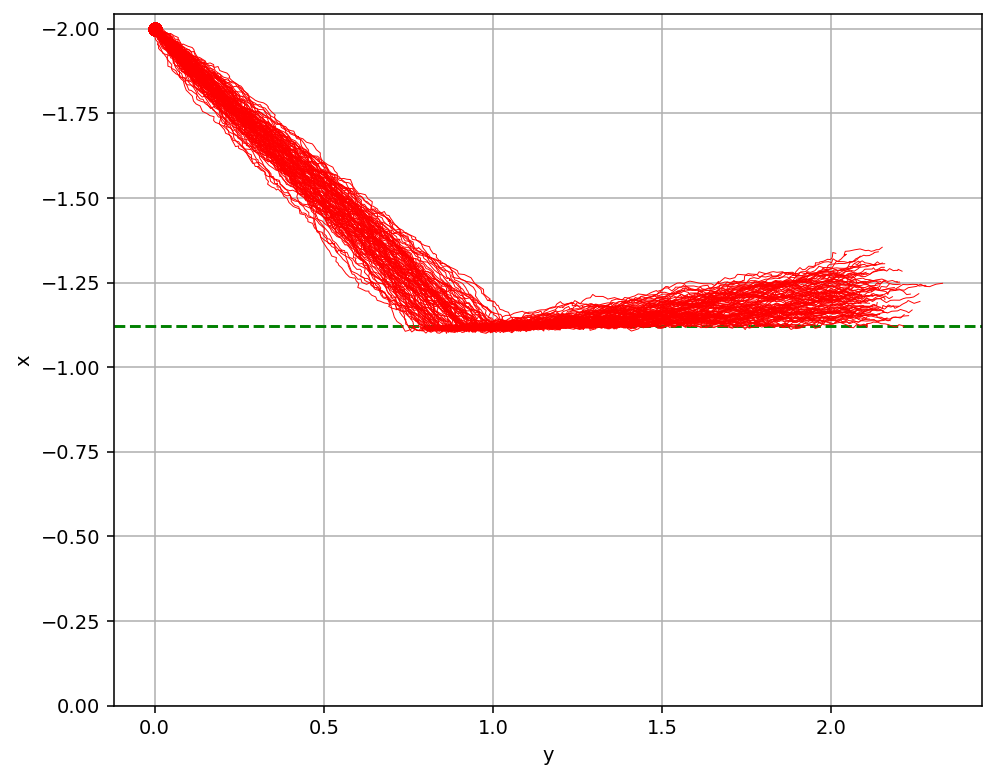

In [47]:
#@njit
def run_abp(n_trajectories, n_steps, dt, x0, y0, phi0,
            Pe, Dt, Dr, force_strength, torque_params
           ):
    
    X = np.zeros((n_trajectories, n_steps))
    Y = np.zeros((n_trajectories, n_steps))
    PHI = np.zeros((n_trajectories, n_steps))

    X[:, 0] = x0
    Y[:, 0] = y0
    PHI[:, 0] = phi0

    for t in range(1, n_steps):

        # Calulate WCA wall force
        F = np.zeros(n_trajectories)
        for k in prange(n_trajectories):
            if X[k, t-1] > -2**(1/6):
                F[k] = -24 * force_strength * (X[k, t-1]**6 - 2) / X[k, t-1]**13

        # Update position

        vx = np.cos(PHI[:, t-1]) * Pe
        vy = np.sin(PHI[:, t-1]) * Pe


        X[:, t] = X[:, t-1] + vx * dt + np.sqrt(2 * Dt * dt) * np.random.normal(size=n_trajectories) + F * dt
        Y[:, t] = Y[:, t-1] + vy * dt + np.sqrt(2 * Dt * dt) * np.random.normal(size=n_trajectories)

        # Update orientation
        torque = np.zeros(n_trajectories)
        for k in prange(n_trajectories):
            torque[k] = Q2 * TORQUE(PHI[k, t-1], torque_params) * F[k]

        PHI[:, t] = PHI[:, t-1] + torque * dt + np.sqrt(2 * Dr * dt) * np.random.normal(size=n_trajectories)

    return X, Y, PHI

def plot_trajectory(x, y, phi):
    plt.figure(figsize=(8, 8))
    plt.plot(y.T[0], x.T[0], 'ro')
    plt.axhline(-2**(1/6), color='g', linestyle='--')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.grid()
    plt.ylim(None, 0)

    tangent_length = 0.5
    n_steps = x.shape[0]
    #for i in range(0, n_steps, 10):
    #    plt.plot([y[i], y[i] + tangent_length*np.sin(phi[i])],
    #             [x[i], x[i] + tangent_length*np.cos(phi[i])],
    #             'b', alpha=0.5, linewidth=0.8)

    plt.plot(y.T, x.T, 'r', lw=0.5)
    plt.xlabel('y')
    plt.ylabel('x')
    plt.gca().invert_yaxis()
    plt.show()


n_trajectories = 100
phi0 = PHI0 # + np.random.randn(n_trajectories)
        
x_data, y_data, phi_data = run_abp(n_trajectories, n_steps, dt, X0, Y0, phi0, PE, DT, DR, FORCE_STRENGTH, [ALPHA, K])
plot_trajectory(x_data, y_data, phi_data)

# Inference

In [5]:
def StructuredResample(w, LUT_accelerator_size = 100):
    
    '''
    Implementing a structured resample.
    We take weights w
    
        w = [w0 w1 ... wN-1]
        
    corresponding to N indices 0..N-1
    
    We then draw N resampled indices, distributed
    according to the provided weights w. The
    resample is structured, meaning that all
    indices are sampled in equidistant steps from
    the CDF.
    
    We start with a random sample <off> and then sample
    in steps from there.
    
    We use a LUT to accelerate finding the appropriate
    region of the CDF faster. The lookup itself is
    implemented in Numba.
    '''
    
    off = np.random.rand() * 1          # First sample offset
    p = w / np.sum(w)                   # Normalized PDF
    cdf = np.cumsum(p)                  # CDF

    idx_rsmpl = np.empty_like(cdf, dtype=int)       # Numba can't allocate memory itself
    LUT = np.empty(LUT_accelerator_size, dtype=int) # """
    
    return __structured_resample_core(cdf, idx_rsmpl, off, LUT)



@njit(inline='always')
def __structured_resample_core(cdf, idx_rsmpl, off, LUT):
    
    ''' Prebuild a LUT for finding the correct position in the CDF faster '''
    nLUT = LUT.shape[0]
    for k in prange(nLUT):
        target_prob = k / nLUT
        idx = 0
        while cdf[idx] < target_prob:
            idx += 1
        LUT[k] = idx
    
    ''' Sample from the CDF '''
    for k in prange(len(cdf)):
        target_prob = (off + k / len(cdf)) % 1
        
        ''' Look up the closest starting (ascending) starting point '''
        idx = LUT[int(target_prob*nLUT)]
        
        ''' Ascend the CDF until we're happy '''
        while cdf[idx] < target_prob:
            idx += 1
        idx_rsmpl[k] = idx

    return idx_rsmpl

## Kalman Filter

100%|██████████| 1/1 [00:00<00:00,  1.84it/s]


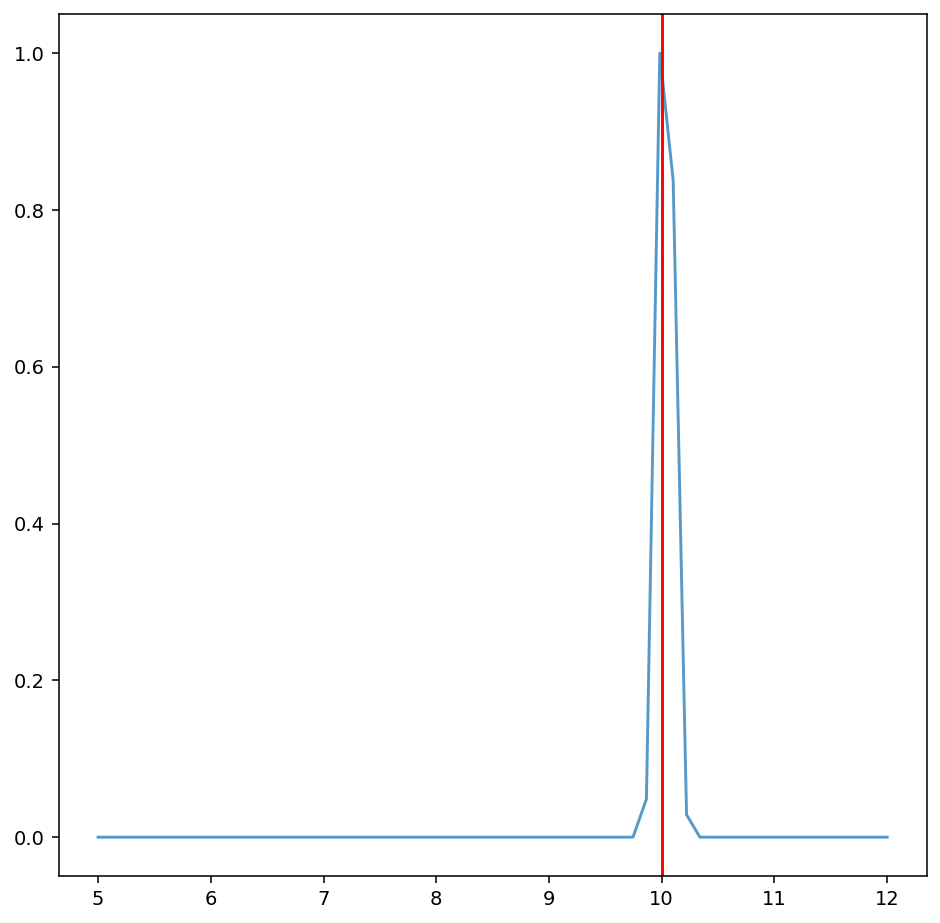

In [69]:
# Calculate the log-likelihood using a Kalman filter
np.set_printoptions(precision=10, suppress=False)
@njit(parallel=True, fastmath=True)
def calc_logl_core_kalman(x, y, dt, Pe, Dt, Dr, force_strength, torque_params):
    n_paramsets = torque_params.shape[0]

    LOGLS = np.zeros(n_paramsets) # Log-likelihoods for each parameter set
    n_datasets = x.shape[0]
    n_steps = x.shape[1]

    phi_means = 0
    phi_stds = 0

    for param_idx in prange(n_paramsets):
        
        params_ = torque_params[param_idx, :]

        logl = 0

        for data_idx in range(n_datasets):
            
            x_ = x[data_idx, :]
            y_ = y[data_idx, :]

            phi_mean = PHI0
            phi_std = 5.0 * np.pi / 180

            for t in range(0, n_steps-1):
                
                F = 0
                if x_[t] > -2**(1/6):
                    F = -24 * force_strength * (x_[t]**6 - 2) / x_[t]**13
                
                x_projection = np.cos(phi_mean) * Pe * dt
                y_projection = np.sin(phi_mean) * Pe * dt
                projection_normalization = np.sqrt(x_projection**2 + y_projection**2)

                x_projected = x_[t] + x_projection
                y_projected = y_[t] + y_projection

                dx = x_projected - (x_[t+1] - F * dt)
                dy = y_projected - y_[t+1]

                offset2 = dx**2 + dy**2
                diffusion_var = 2 * Dt * dt
                uncertainty_var = (phi_std * Pe * dt)**2
                logl += -0.5 * offset2 / (diffusion_var + uncertainty_var)

                offset = (-dy * x_projection / projection_normalization) + (dx * y_projection / projection_normalization)
                phi_offset_mean = offset / (Pe * dt)
                phi_offset_std = np.sqrt(2 * Dt * dt) / (Pe * dt)
                
                phi_mean = (phi_std**2 * (phi_mean + phi_offset_mean) + phi_offset_std**2 * phi_mean) / (phi_std**2 + phi_offset_std**2)
                phi_std = np.sqrt(1 / (1/phi_std**2 + 1/phi_offset_std**2) + 2 * Dr * dt)
                torque = Q2 * TORQUE(phi_mean, params_) * F
                d_torque = Q2 * TORQUE_DERIV(phi_mean, params_) * F
                phi_mean += torque * dt
                phi_std *= np.exp(-d_torque * dt)

            #phi_means.append(phi_mean)
            #phi_stds.append(phi_std)

        
        LOGLS[param_idx] = logl
        #break
    
    return LOGLS, phi_means, phi_stds

n_paramsets = 60
params = np.ones((n_paramsets, 2))
alphas = np.linspace(0.5 * ALPHA, 1.2 * ALPHA, n_paramsets)
params[:, 0] = alphas
params[:, 1] = K

for _ in tqdm(range(1)):
    logls, phi_mean, phi_std = calc_logl_core_kalman(x_data, y_data, dt, PE, DT, DR, FORCE_STRENGTH, params)
    logls -= logls.max()
    p = np.exp(logls)
    plt.plot(alphas, p, alpha=0.75)

plt.axvline(ALPHA, color='r')

# Particle Filter

100%|██████████| 1/1 [00:04<00:00,  4.84s/it]


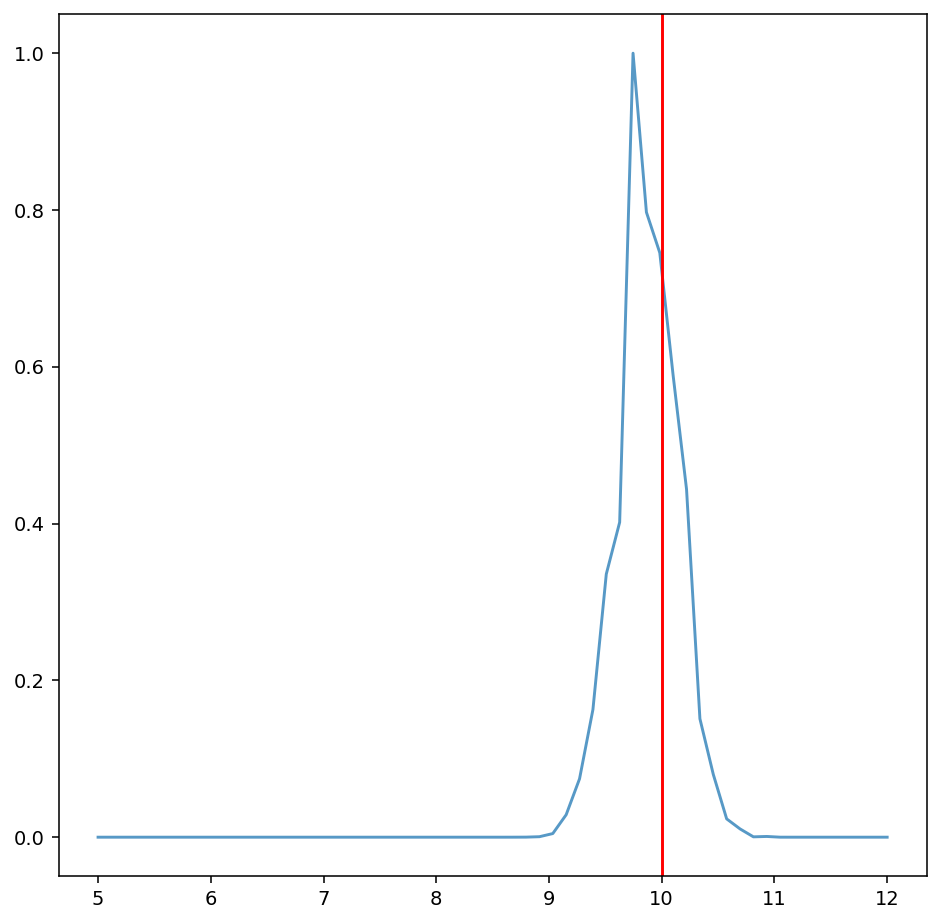

In [25]:
# Calculate the log-likelihood using a particle filter
np.set_printoptions(precision=10, suppress=False)
@njit(parallel=True, fastmath=True)
def calc_logl_core(x, y, dt, Pe, Dt, Dr, force_strength, torque_params, n_particles=100):
    n_paramsets = torque_params.shape[0]

    LOGLS = np.zeros(n_paramsets) # Log-likelihoods for each parameter set
    n_datasets = x.shape[0]
    n_steps = x.shape[1]

    phi_means = list()
    phi_stds = list()

    for param_idx in prange(n_paramsets):
        
        params_ = torque_params[param_idx, :]

        logl = 0

        for data_idx in range(n_datasets):
            
            x_ = x[data_idx, :]
            y_ = y[data_idx, :]
            phi_ = phi_data[data_idx, :]

            phi = PHI0 + np.random.randn(n_particles) * 1 * np.pi / 180

            phi_mean = list()
            phi_std = list()

            for t in range(0, n_steps-1):

                F = 0
                if x_[t] > -2**(1/6):
                    F = -24 * force_strength * (x_[t]**6 - 2) / x_[t]**13
                
                x_projection = np.cos(phi) * Pe * dt
                y_projection = np.sin(phi) * Pe * dt

                x_projected = x_[t] + x_projection
                y_projected = y_[t] + y_projection

                dx = x_projected - (x_[t+1] - F * dt)
                dy = y_projected - y_[t+1]

                offset2 = dx**2 + dy**2
                diffusion_var = 2 * Dt * dt

                particle_logls = -0.5 * offset2 / diffusion_var
                
                idx_max_particle_logl = np.argmax(particle_logls)
                max_particle_logl = particle_logls[idx_max_particle_logl]
                logl_rest = np.delete(particle_logls, [idx_max_particle_logl])
                logl += max_particle_logl + np.log(1 + np.sum(np.exp(logl_rest - max_particle_logl)))

                particle_logls -= particle_logls.max()
                particle_weights = np.exp(particle_logls)
                particle_weights /= particle_weights.sum()

                #resampled_indices = np.random.choice(np.arange(n_particles), size=n_particles, p=particle_weights)

                off = np.random.rand() * 1
                cdf = np.cumsum(particle_weights)
                resampled_indices = np.zeros(n_particles, dtype=np.uint32)
                LUT = np.zeros(100, dtype=np.uint32)

                __structured_resample_core(cdf, resampled_indices, off, LUT)

                phi = phi[resampled_indices]

                for k in prange(n_particles):
                    torque = Q2 * TORQUE(phi[k], params_) * F
                    phi[k] += torque * dt + np.sqrt(2 * Dr * dt) * np.random.normal()

                phi_mean.append(np.mean(phi))
                phi_std.append(np.std(phi))

            phi_means.append(phi_mean)
            phi_stds.append(phi_std)

        LOGLS[param_idx] = logl
        #break
    
    return LOGLS, phi_means, phi_stds

n_paramsets = 60
params = np.ones((n_paramsets, 2))
alphas = np.linspace(0.5 * ALPHA, 1.2 * ALPHA, n_paramsets)
params[:, 0] = alphas
params[:, 1] = K


for _ in tqdm(range(1)):
    logls, phi_mean, phi_std = calc_logl_core(x_data, y_data, dt, PE, DT, DR, FORCE_STRENGTH, params, n_particles=1500)
    logls -= logls.max()
    p = np.exp(logls)
    plt.plot(alphas, p, alpha=0.75)

plt.axvline(ALPHA, color='r')

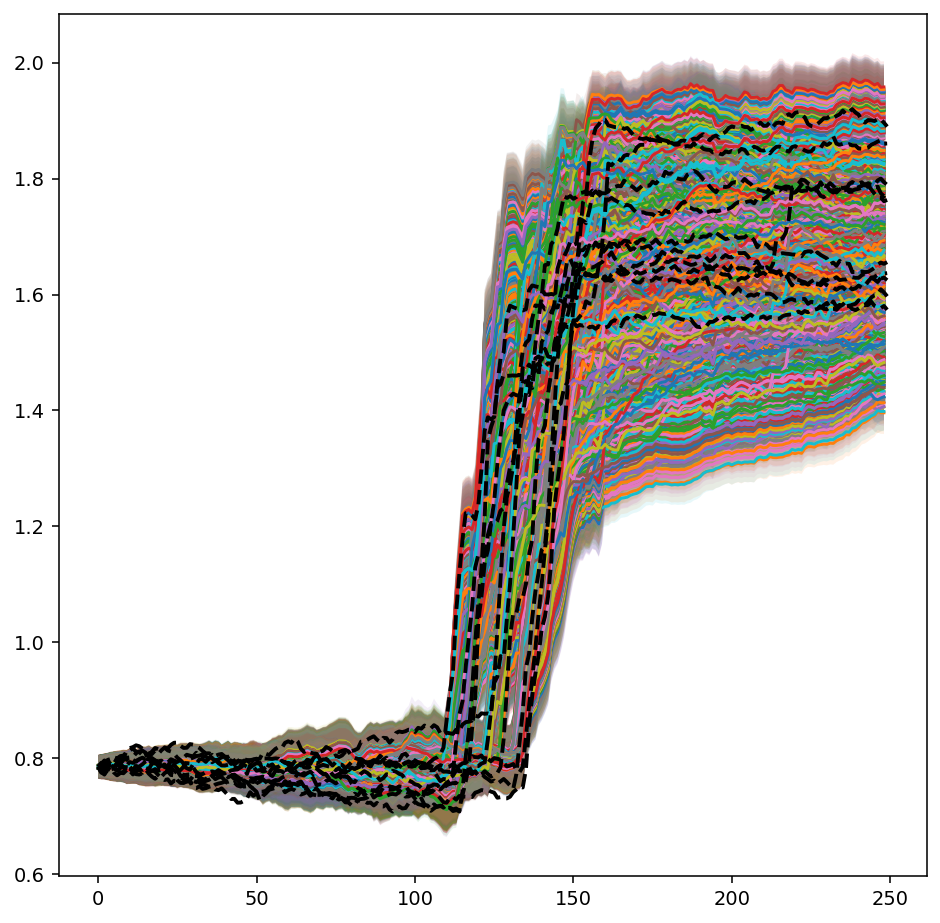

In [8]:
# plot all phi_means with bands around them
for phi_mean_, phi_std_ in zip(phi_mean, phi_std):
    plt.plot(phi_mean_)
    plt.fill_between(np.arange(len(phi_mean_)),
                     np.array(phi_mean_) - np.array(phi_std_),
                     np.array(phi_mean_) + np.array(phi_std_),
                     alpha=0.1)
    
plt.plot(phi_data[:, :].T, '--k', lw=2);

# Sketch the distribution

In [73]:
res = 150
alpha_grid = np.linspace(0.3 * ALPHA, 5 * ALPHA, res)
k_grid = np.linspace(0.3 * K, 5 * K, res)

logls = []
for alpha_ in tqdm(alpha_grid):
    for k_ in k_grid:
        logl, _, _ = calc_logl_core_kalman(x_data, y_data, dt, PE, DT, DR, FORCE_STRENGTH, np.atleast_2d([alpha_, k_]))
        logls.append(logl)
    

100%|██████████| 150/150 [00:37<00:00,  4.03it/s]


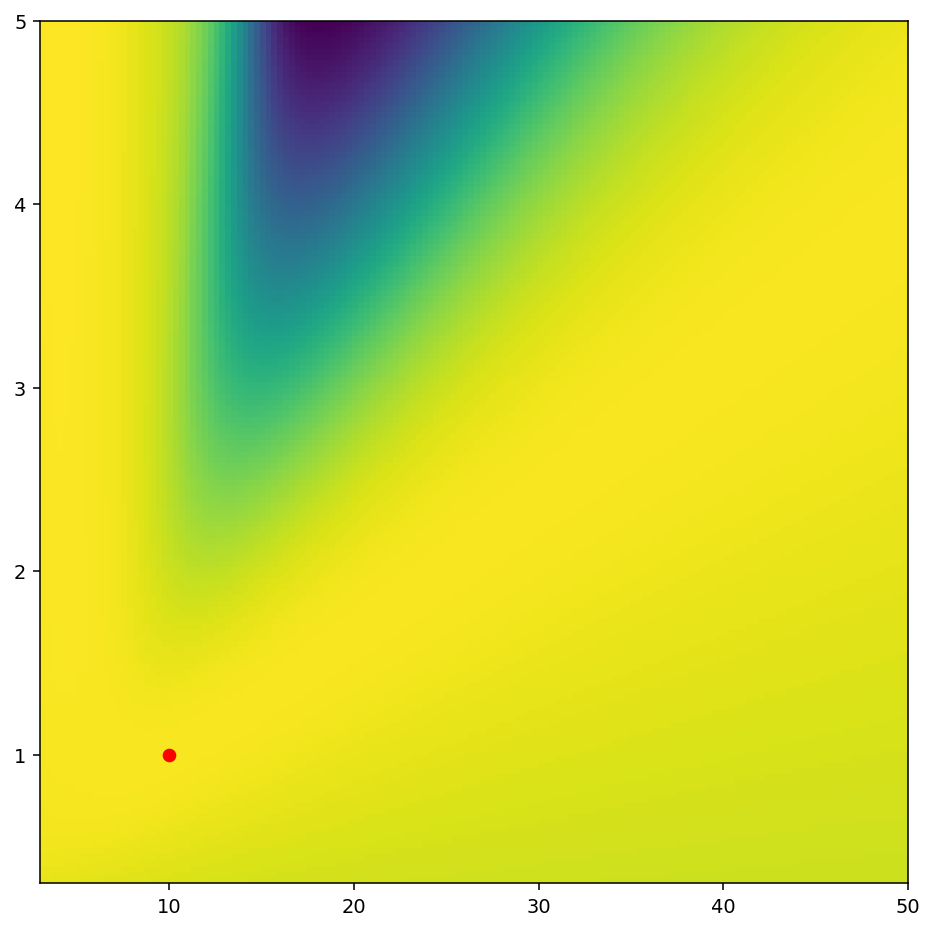

In [74]:
logls = np.array(logls).reshape(res, res)
plt.imshow(logls, extent=[alpha_grid.min(), alpha_grid.max(), k_grid.min(), k_grid.max()], aspect='auto', origin='lower')
plt.plot(ALPHA, K, 'ro')

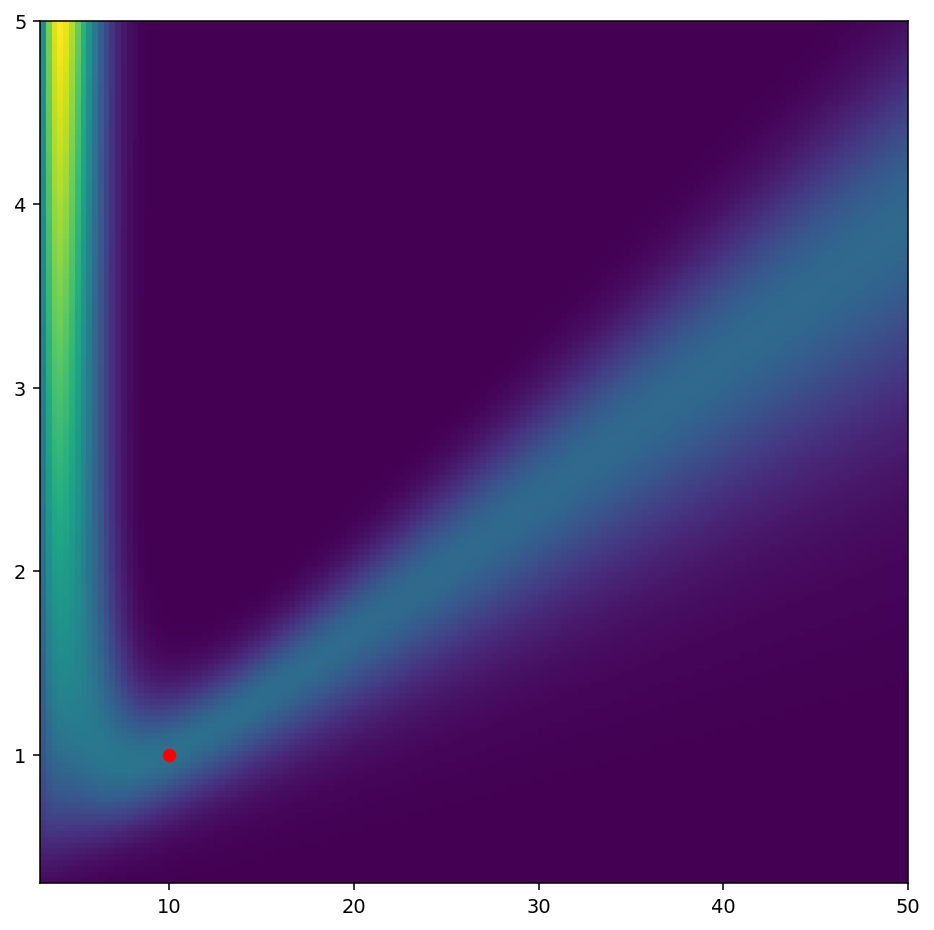

In [75]:
ps = np.exp((logls - logls.max())/1000)
ps /= ps.sum()
plt.imshow(ps, extent=[alpha_grid.min(), alpha_grid.max(), k_grid.min(), k_grid.max()], aspect='auto', origin='lower')
plt.plot(ALPHA, K, 'ro')

# MCMC

Markov-Chain sampler for the posterior (using a flat prior).

In [12]:
def mcmc(x_data, y_data, n_samples=1000, alpha_mutation=1e-3, k_mutation=1e-3, superstep=100, n_particles=150):
    
    ALPHA_CHAIN = []
    K_CHAIN = []

    alpha = ALPHA
    k = K
    
    LOGL = -np.inf # Current chain likelihood
    attempts = 0
    accepts = 0
    pbar = tqdm(range(n_samples * superstep), leave=False)
    for s in pbar:
    
        # GIBBS ALPHA
        alpha_prop = alpha + np.random.randn() * alpha_mutation # Propose new alpha
        params = np.atleast_2d([alpha_prop, k])
        LOGL_prop, _, _ = calc_logl_core(x_data, y_data, dt, PE, DT, DR, FORCE_STRENGTH, params, n_particles=n_particles)
        attempts += 1
        thresh = np.exp(LOGL_prop - LOGL)
        a = np.random.rand()
        if a < thresh:
            accepts += 1
            LOGL = LOGL_prop
            alpha = alpha_prop
    
        # GIBBS K
        k_prop = k + np.random.randn() * k_mutation # Propose new k
        params = np.atleast_2d([alpha, k_prop])
        LOGL_prop, _, _ = calc_logl_core(x_data, y_data, dt, PE, DT, DR, FORCE_STRENGTH, params, n_particles=n_particles)
        attempts += 1
        thresh = np.exp(LOGL_prop - LOGL)
        a = np.random.rand()
        if a < thresh:
            accepts += 1
            LOGL = LOGL_prop
            k = k_prop
    
        if not s % superstep:
            ALPHA_CHAIN.append(alpha)
            K_CHAIN.append(k)
            pbar.set_description(f"Acceptance: {int(100*accepts/attempts)}%. Progress")

    return ALPHA_CHAIN, K_CHAIN

In [13]:
ALPHA_CHAIN, K_CHAIN = mcmc(x_data, y_data, n_samples=1000, alpha_mutation=1e-1, k_mutation=1e-1, superstep=1, n_particles=15)
ALPHA_CHAIN = np.array(ALPHA_CHAIN)
K_CHAIN = np.array(K_CHAIN)

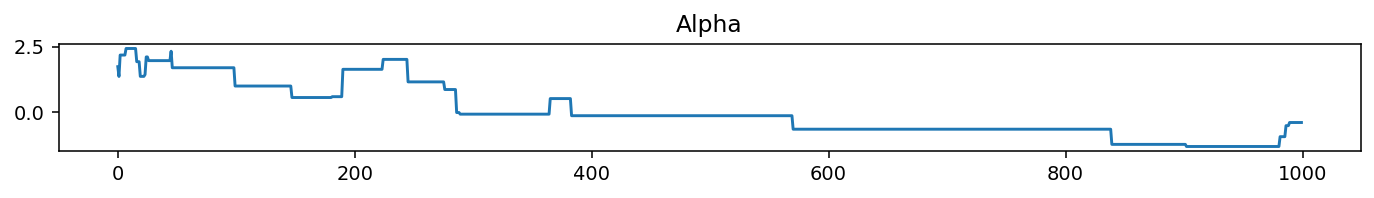

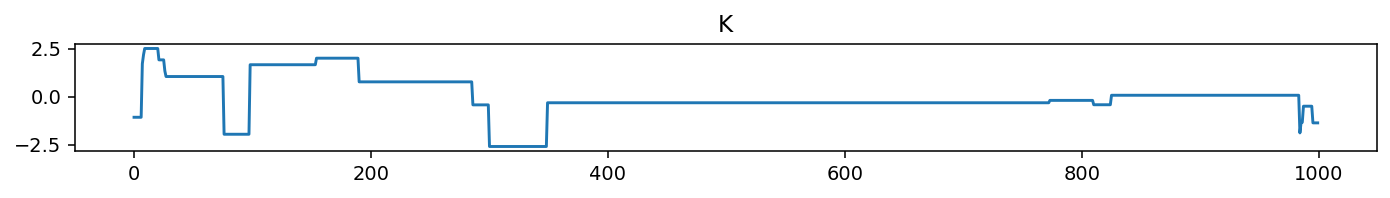

In [14]:
# plot the traces
plt.figure(figsize=(12, 1))
ALPHA_CHAIN_normalized = (ALPHA_CHAIN - ALPHA_CHAIN.mean()) / ALPHA_CHAIN.std()
plt.plot(ALPHA_CHAIN_normalized)
plt.title('Alpha')
plt.show()
plt.figure(figsize=(12, 1))
K_CHAIN_normalized = (K_CHAIN - K_CHAIN.mean()) / K_CHAIN.std()
plt.plot(K_CHAIN_normalized)
plt.title('K')

plt.show()

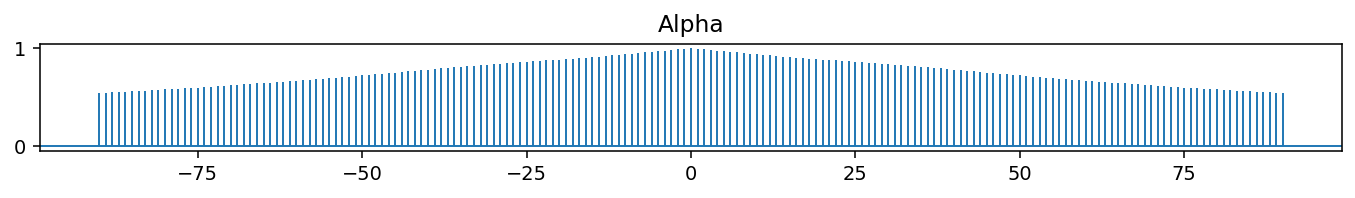

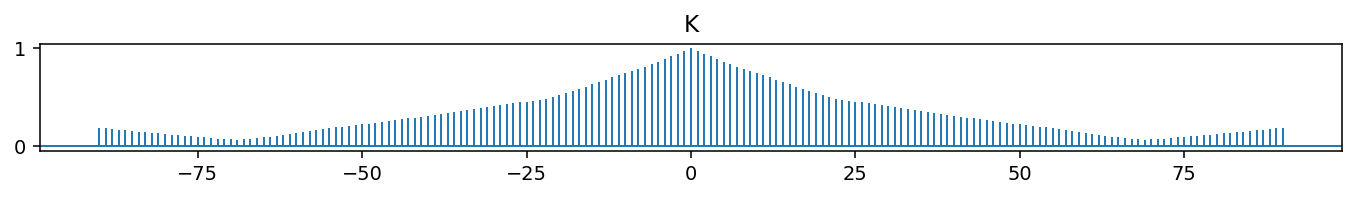

In [15]:
maxlags = 90
plt.figure(figsize=(12, 1))
plt.acorr(ALPHA_CHAIN - ALPHA_CHAIN.mean(), maxlags=maxlags, usevlines=True, normed=True, lw=1)
plt.title('Alpha')
plt.show()
plt.figure(figsize=(12, 1))
plt.acorr(K_CHAIN - K_CHAIN.mean(), maxlags=maxlags, usevlines=True, normed=True, lw=1)
plt.title('K')
plt.show()